# Lab 3 · Object detection with Faster R-CNN and YOLO

**Course lab:** `CV-Week3-Lecture3.ipynb` (in `course-files/labs/`)
**Theory partner:** [notes/04_object_detection_rcnn_yolo_ssd.md](../notes/04_object_detection_rcnn_yolo_ssd.md) and [notebooks/04_object_detection_rcnn_yolo_ssd.ipynb](../notebooks/04_object_detection_rcnn_yolo_ssd.ipynb)

The course notebook has three code cells. This lab runs all three for real, fixes what breaks, and explains every line:

| Course cell | What it does | What you will see here |
|---|---|---|
| Setup: COCO dataset loader | load COCO images + box annotations with `CocoDetection` | the loader working on **real COCO images and labels**, plus the two bugs it hides |
| Exercise: pretrained Faster R-CNN | run a two-stage detector on a batch | the output format (`boxes`, `labels`, `scores`), score thresholds, drawn detections |
| Mini project: YOLO detector | `YOLO('yolov5s.pt')` on a picture | labelled boxes, a count per class, the `conf`/`iou` knobs, a speed race and a confidence-threshold sweep with precision and recall |

**What you will learn:** how a detector's output is structured, how to load COCO properly, why a score threshold is needed, what NMS does in practice, and how to measure precision/recall rather than just looking at pictures.

**Run time:** about 4–5 minutes on a 4-core laptop CPU (most of it is running two YOLO models over 128 images). On a Colab GPU: under a minute.

## 0 · Theory in 60 seconds (details in notes chapter 04)

- **Object detection = what + where:** for every object, a **class label**, a **bounding box** `(x1, y1, x2, y2)` and a **confidence score**.
- **Two-stage (R-CNN family → Faster R-CNN):** stage 1, a *Region Proposal Network* suggests ~1000 boxes that might contain something; stage 2 classifies each proposal and refines its box. Accurate, slower.
- **One-stage (YOLO, SSD):** a single network pass predicts boxes and classes for a grid of positions at once. Fast, nearly as accurate today.
- **Both** produce many overlapping guesses, then use a **score threshold** (drop unsure boxes) and **NMS** (*non-maximum suppression*: keep the best box, delete boxes that overlap it by more than an IoU threshold).
- **IoU** (*intersection over union*) = overlap area / union area. A detection counts as correct when IoU with a true box ≥ 0.5.

> **Two routes for the downloads.** The course uses torchvision's pretrained Faster R-CNN (weights from `download.pytorch.org`) and the full COCO dataset (from `images.cocodataset.org`, ~20 GB). On a normal internet connection both work and this notebook uses them. The machine that produced the outputs below **could not reach those two servers**, so every download cell tries the course's route first and, if it fails, falls back to something that *is* reachable (Ultralytics' **COCO128**: the first 128 images of COCO train2017 with their labels, and a **YOLOv8n** model instead of Faster R-CNN). Each cell prints which route ran.

In [1]:
%matplotlib inline
import os, json, time, glob, zipfile, urllib.request
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import torch
import torchvision
import torchvision.transforms as transforms

torch.manual_seed(0)
torch.set_num_threads(2)              # share the CPU politely; on your own laptop you can raise this
DATA = "data"                         # every download goes here (git-ignored)
os.makedirs(DATA, exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| device:", device)

def download(url, dest):
    """Download url to dest once (skip if the file is already there)."""
    if not os.path.exists(dest):
        os.makedirs(os.path.dirname(dest) or ".", exist_ok=True)
        urllib.request.urlretrieve(url, dest)
    return dest

torch 2.14.1+cu130 | torchvision 0.29.1+cu130 | device: cpu


## 1 · Setup: the COCO dataset loader

**COCO** (*Common Objects in Context*) is the standard detection benchmark: 80 everyday classes (person, car, dog, cup, …), ~118,000 training photos and 5,000 validation photos, each with every object boxed. Annotations live in one big JSON file per split with three lists:

```
images:      [{"id": 9, "file_name": "000000000009.jpg", "width": 640, "height": 480}, ...]
annotations: [{"image_id": 9, "bbox": [x, y, w, h], "category_id": 51, "area": ..., "iscrowd": 0}, ...]
categories:  [{"id": 1, "name": "person"}, {"id": 2, "name": "bicycle"}, ...]
```

Two details trip everybody up:
- COCO boxes are **`[x, y, width, height]`** (top-left corner + size). torchvision models want **`[x1, y1, x2, y2]`** (two corners).
- Category ids run **1…90 with gaps** (80 real classes; 10 ids were dropped). **id 1 = person**, 3 = car, 18 = dog. torchvision detectors output these same ids.

**On your own machine (the course's route):** download `val2017.zip` (1 GB, 5,000 images) and `annotations_trainval2017.zip` (241 MB) from cocodataset.org and unzip so you have `data/coco_data/val2017/*.jpg` and `data/coco_data/annotations/instances_val2017.json`. Use **val2017**, not train2017 (18 GB): it is smaller *and* the pretrained models never trained on it, so results are honest. The cell below uses it automatically if it finds it.

**Fallback (used here):** COCO128 from Ultralytics' GitHub releases (7 MB) ships images + labels in YOLO's text format. We convert those labels into a real COCO-style JSON, so the course's `CocoDetection` loader runs **unchanged** on real COCO photos.

In [2]:
from ultralytics.data.converter import coco80_to_coco91_class     # YOLO class 0..79  ->  COCO id 1..90
COCO_NAMES = torchvision.models.detection.FasterRCNN_ResNet50_FPN_Weights.DEFAULT.meta["categories"]  # index = COCO id (no download needed)

coco_root = os.path.join(DATA, "coco_data")
official_imgs = os.path.join(coco_root, "val2017")
official_ann = os.path.join(coco_root, "annotations", "instances_val2017.json")

def build_coco128(coco_root):
    """Fallback: download COCO128 and write its labels as a COCO-format instances JSON."""
    z = download("https://github.com/ultralytics/assets/releases/download/v0.0.0/coco128.zip", os.path.join(DATA, "coco128.zip"))
    if not os.path.isdir(os.path.join(DATA, "coco128")):
        zipfile.ZipFile(z).extractall(DATA)
    img_dir = os.path.join(DATA, "coco128", "images", "train2017")
    ann_file = os.path.join(coco_root, "annotations", "instances_coco128.json")
    if not os.path.exists(ann_file):
        to91 = coco80_to_coco91_class()
        images, anns = [], []
        for f in sorted(os.listdir(img_dir)):
            w, h = Image.open(os.path.join(img_dir, f)).size
            img_id = int(f.split(".")[0])
            images.append({"id": img_id, "file_name": f, "width": w, "height": h})
            lbl = os.path.join(DATA, "coco128", "labels", "train2017", f.replace(".jpg", ".txt"))
            if os.path.exists(lbl):
                for line in open(lbl).read().split("\n"):
                    if not line.strip():
                        continue
                    c, xc, yc, bw, bh = map(float, line.split())          # YOLO format: class, centre x/y, w, h (all 0..1)
                    box = [(xc - bw / 2) * w, (yc - bh / 2) * h, bw * w, bh * h]   # -> COCO [x, y, w, h] in pixels
                    anns.append({"id": len(anns) + 1, "image_id": img_id, "category_id": to91[int(c)],
                                 "bbox": [round(v, 2) for v in box], "area": box[2] * box[3], "iscrowd": 0})
        cats = [{"id": i, "name": n} for i, n in enumerate(COCO_NAMES) if n not in ("__background__", "N/A")]
        os.makedirs(os.path.dirname(ann_file), exist_ok=True)
        json.dump({"images": images, "annotations": anns, "categories": cats}, open(ann_file, "w"))
    return img_dir, ann_file

if os.path.exists(official_ann):
    img_dir, ann_file = official_imgs, official_ann
    print("ROUTE: official COCO val2017 found on disk")
else:
    img_dir, ann_file = build_coco128(coco_root)
    print("ROUTE: fallback, COCO128 (first 128 images of COCO train2017) converted to COCO JSON")
print("images:", img_dir, "| annotations:", ann_file)

ROUTE: fallback, COCO128 (first 128 images of COCO train2017) converted to COCO JSON
images: data/coco128/images/train2017 | annotations: data/coco_data/annotations/instances_coco128.json


### 1a · The course's loader, exactly as written

```python
transform = transforms.Compose([transforms.Resize((224,224)), transforms.ToTensor()])
trainset = CocoDetection(root=..., annFile=..., transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=4, shuffle=True)
```

- `CocoDetection(root, annFile, transform)` returns `(image, target)` where **`target` is a list of annotation dicts**, one per object in that image (needs `pip install pycocotools`).
- `transform` is applied **to the image only**. The boxes in `target` are not touched.
- `DataLoader(batch_size=4)` groups 4 samples. By default it tries to **stack** them into tensors (`default_collate`).

Let's run it and ask for one batch.

In [3]:
from torchvision.datasets import CocoDetection

transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor()
])
trainset = CocoDetection(root=img_dir, annFile=ann_file, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=4, shuffle=True)
print("Loaded COCO dataset with", len(trainset), "images")

try:
    images, targets = next(iter(trainloader))
    print("batch loaded (this only happens if all 4 images have the same number of objects)")
except Exception as e:
    print("COURSE LOADER FAILS ->", type(e).__name__ + ":", str(e)[:160])

loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
Loaded COCO dataset with 128 images
COURSE LOADER FAILS -> RuntimeError: each element in list of batch should be of equal size


**Bug 1, the batch cannot be built.** Image 1 may have 3 objects and image 2 may have 12. `default_collate` tries to stack the four `target` lists into one tensor and fails because their lengths differ. Detection data is *ragged*, so detection code always uses a custom `collate_fn` that simply keeps the samples in tuples:

```python
collate_fn=lambda batch: tuple(zip(*batch))   # -> (img1, img2, img3, img4), (target1, ..., target4)
```

**Bug 2, the boxes no longer match the picture.** `Resize((224,224))` squashes the image, but the boxes in `target` are still in the original pixel coordinates. Look:

loading annotations into memory...
Done (t=0.00s)
creating index...
index created!


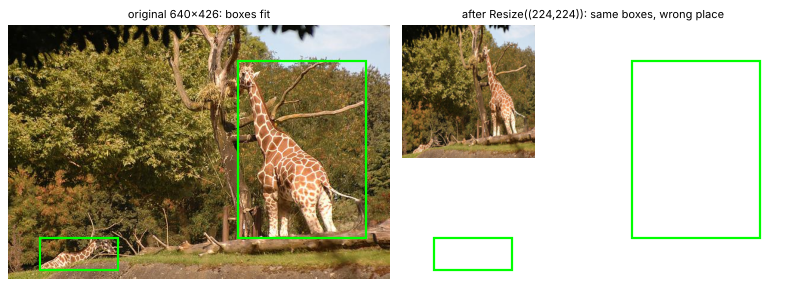

objects in this image: ['giraffe', 'giraffe']


In [4]:
raw = CocoDetection(root=img_dir, annFile=ann_file)          # no transform: PIL image + annotation list
img, target = raw[1]
small = img.resize((224, 224))

fig, ax = plt.subplots(1, 2, figsize=(10, 4), dpi=80)
for a, im, title in [(ax[0], img, f"original {img.size[0]}x{img.size[1]}: boxes fit"),
                     (ax[1], small, "after Resize((224,224)): same boxes, wrong place")]:
    a.imshow(im); a.set_title(title, fontsize=10); a.axis("off")
    for t in target:
        x, y, w, h = t["bbox"]
        a.add_patch(patches.Rectangle((x, y), w, h, fill=False, ec="lime", lw=2))
    a.set_xlim(0, img.size[0] if im is img else 224); a.set_ylim(im.size[1], 0)
ax[1].set_xlim(0, img.size[0]); ax[1].set_ylim(img.size[1], 0)
plt.tight_layout(); plt.show()
print("objects in this image:", [COCO_NAMES[t['category_id']] for t in target])

On the right the picture now covers only the top-left 224×224 pixels, but the boxes still use the original coordinates, so they no longer sit on the objects. If you trained on that, the model would learn nonsense. Two correct options:
1. **Don't resize at all** for torchvision detectors. Faster R-CNN resizes internally (shorter side → 800 px) and maps its boxes back to *your* image's coordinates. YOLO letterboxes to 640 internally and does the same.
2. If you must resize (e.g. for training your own model), resize the boxes by the same x and y factors (torchvision's `transforms.v2` can do this for you when boxes are wrapped as `tv_tensors.BoundingBoxes`).

### 1b · The fixed loader

In [5]:
transform = transforms.Compose([transforms.ToTensor()])        # FIX: no Resize - the detector handles sizes itself
trainset = CocoDetection(root=img_dir, annFile=ann_file, transform=transform)
g = torch.Generator().manual_seed(0)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=4, shuffle=True, generator=g,
                                          collate_fn=lambda batch: tuple(zip(*batch)))   # FIX: keep ragged targets as tuples

images, targets = next(iter(trainloader))
print("Loaded COCO dataset with", len(trainset), "images")
for img, tgt in zip(images, targets):
    names = Counter(COCO_NAMES[t["category_id"]] for t in tgt)
    print(f"image {tuple(img.shape)} (C,H,W, values {img.min():.0f}..{img.max():.0f}) | {len(tgt):2d} objects: {dict(names)}")

def coco_to_xyxy(tgt):
    """COCO [x,y,w,h] annotations -> tensor of [x1,y1,x2,y2] boxes + tensor of labels (what torchvision models use)."""
    b = torch.tensor([t["bbox"] for t in tgt], dtype=torch.float32).reshape(-1, 4)
    b[:, 2:] += b[:, :2]
    return b, torch.tensor([t["category_id"] for t in tgt], dtype=torch.int64)

loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
Loaded COCO dataset with 128 images
image (3, 480, 640) (C,H,W, values 0..1) | 11 objects: {'bed': 1, 'teddy bear': 10}
image (3, 480, 640) (C,H,W, values 0..1) |  3 objects: {'dog': 1, 'car': 1, 'frisbee': 1}
image (3, 640, 591) (C,H,W, values 0..1) |  2 objects: {'elephant': 2}
image (3, 488, 640) (C,H,W, values 0..1) |  5 objects: {'person': 3, 'elephant': 2}


Each image keeps its own size (COCO photos are about 640×480) and its own number of objects. That is exactly what detection models expect: **a list of `[3, H, W]` tensors with values 0–1**, not one stacked tensor.

## 2 · Exercise: detect objects with a pretrained Faster R-CNN

The course writes `detection.fasterrcnn_resnet50_fpn(pretrained=True)`. In torchvision ≥ 0.13 `pretrained=` is **deprecated** (and gives a warning, or an error in newer versions); the modern form is `weights="DEFAULT"` (= `FasterRCNN_ResNet50_FPN_Weights.COCO_V1`, 37.0 box mAP on COCO val2017, 41.8 M parameters, ~160 MB download).

**What the model returns:** for a list of N images, a list of N dicts:

| key | shape | meaning |
|---|---|---|
| `boxes` | `[K, 4]` float | `x1, y1, x2, y2` in the pixel coordinates of **your** input image |
| `labels` | `[K]` int | COCO category id (1 = person, 3 = car, …) |
| `scores` | `[K]` float | confidence 0–1, sorted high → low |

torchvision keeps every box with score ≥ 0.05 (`box_score_thresh`) after NMS at IoU 0.5 (`box_nms_thresh`), up to 100 per image. So `len(output['boxes'])` (what the course prints) **counts lots of unsure junk**; you normally keep `scores > 0.5` or so.

The cell tries the course's model first. If the weights can't be downloaded it falls back to **YOLOv8n** wrapped so that it returns *exactly the same dict format*, so all the following code is identical for both routes.

In [6]:
import torchvision.models.detection as detection
from ultralytics import YOLO

def yolo_as_torchvision(yolo, conf=0.05, iou=0.5):
    """Wrap an Ultralytics YOLO model so it takes/returns the same things as a torchvision detector."""
    to91 = coco80_to_coco91_class()
    def run(images):
        outs = []
        for img in images:                                     # img: [3,H,W] float tensor 0..1 (RGB)
            arr = (img.permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)[:, :, ::-1]   # -> HxWx3 uint8 BGR
            r = yolo.predict(arr, conf=conf, iou=iou, verbose=False)[0]
            outs.append({"boxes": r.boxes.xyxy.cpu(),
                         "labels": torch.tensor([to91[int(c)] for c in r.boxes.cls], dtype=torch.int64),
                         "scores": r.boxes.conf.cpu()})
        return outs
    return run

try:
    model = detection.fasterrcnn_resnet50_fpn(weights="DEFAULT")    # FIX: weights= instead of pretrained=True
    model.eval()                                                     # inference mode (batch-norm/dropout frozen)
    model.to(device)
    detector, DETECTOR_NAME = model, "Faster R-CNN ResNet50-FPN (torchvision)"
    print("ROUTE: course model, Faster R-CNN with COCO weights")
except Exception as e:
    print("Faster R-CNN weights unavailable ->", type(e).__name__, str(e)[:90])
    yolo8 = YOLO(os.path.join(DATA, "yolov8n.pt"))                   # downloads from github.com/ultralytics/assets
    detector, DETECTOR_NAME = yolo_as_torchvision(yolo8), "YOLOv8n (fallback)"
    print("ROUTE: fallback, YOLOv8n with the same output format")

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth
Faster R-CNN weights unavailable -> URLError <urlopen error Tunnel connection failed: 403 Forbidden>


ROUTE: fallback, YOLOv8n with the same output format


In [7]:
# Run detection on a batch (the course's code, plus no_grad and a score threshold)
images_dev = [img.to(device) for img in images]
with torch.no_grad():                                 # FIX: no gradients needed for inference (faster, less memory)
    outputs = detector(images_dev)

SCORE_THRESH = 0.5
print("Detector:", DETECTOR_NAME)
print("Detected objects in batch:")
for i, (output, tgt) in enumerate(zip(outputs, targets)):
    keep = output["scores"] > SCORE_THRESH
    print(f"Image {i}: {len(output['boxes']):3d} boxes returned, {int(keep.sum()):2d} with score > {SCORE_THRESH}"
          f"  | ground truth: {len(tgt)} objects")

o = outputs[0]
print("\nkeys:", list(o.keys()))
print("first 3 detections of image 0:")
for b, l, s in zip(o["boxes"][:3], o["labels"][:3], o["scores"][:3]):
    print(f"  box={[round(v) for v in b.tolist()]}  label={int(l)} ({COCO_NAMES[int(l)]})  score={s:.2f}")

Detector: YOLOv8n (fallback)
Detected objects in batch:
Image 0:  19 boxes returned,  4 with score > 0.5  | ground truth: 11 objects
Image 1:   3 boxes returned,  3 with score > 0.5  | ground truth: 3 objects
Image 2:   2 boxes returned,  1 with score > 0.5  | ground truth: 2 objects
Image 3:   7 boxes returned,  1 with score > 0.5  | ground truth: 5 objects

keys: ['boxes', 'labels', 'scores']
first 3 detections of image 0:
  box=[181, 192, 286, 286]  label=88 (teddy bear)  score=0.65
  box=[398, 284, 527, 391]  label=88 (teddy bear)  score=0.59
  box=[261, 282, 336, 362]  label=88 (teddy bear)  score=0.54


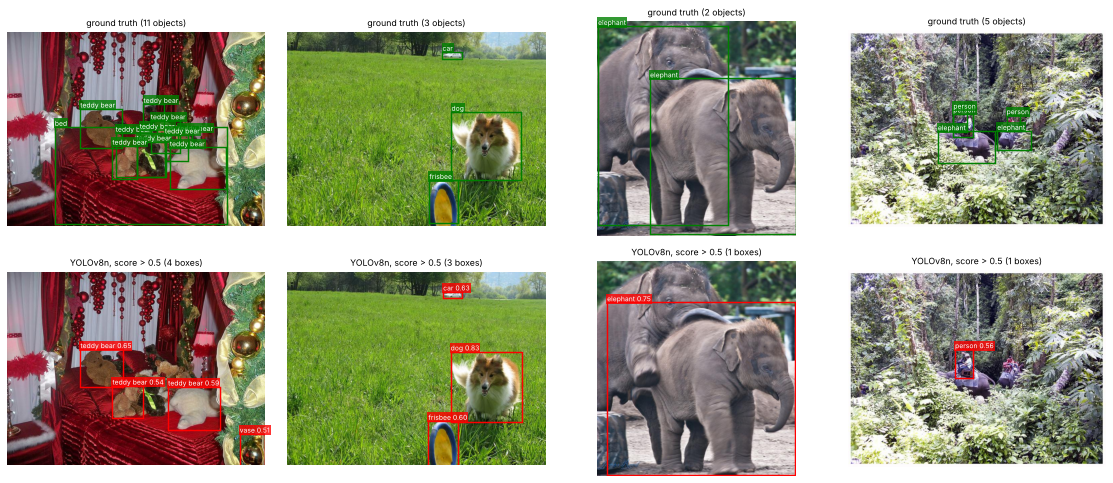

image 0: predicted {'teddy bear': 3, 'vase': 1}
         true      {'bed': 1, 'teddy bear': 10}
image 1: predicted {'dog': 1, 'car': 1, 'frisbee': 1}
         true      {'dog': 1, 'car': 1, 'frisbee': 1}
image 2: predicted {'elephant': 1}
         true      {'elephant': 2}
image 3: predicted {'person': 1}
         true      {'person': 3, 'elephant': 2}


In [8]:
def draw(ax, img, boxes, labels, scores=None, color="red", title=""):
    ax.imshow(img.permute(1, 2, 0) if torch.is_tensor(img) else img); ax.axis("off"); ax.set_title(title, fontsize=9)
    for k, (b, l) in enumerate(zip(boxes, labels)):
        x1, y1, x2, y2 = [float(v) for v in b]
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec=color, lw=1.5))
        txt = COCO_NAMES[int(l)] + (f" {float(scores[k]):.2f}" if scores is not None else "")
        ax.text(x1, y1 - 3, txt, color="white", fontsize=7, bbox=dict(fc=color, ec="none", pad=1, alpha=0.8))

fig, ax = plt.subplots(2, 4, figsize=(16, 7), dpi=70)
for i in range(4):
    gb, gl = coco_to_xyxy(targets[i])
    draw(ax[0, i], images[i], gb, gl, color="green", title=f"ground truth ({len(gl)} objects)")
    keep = outputs[i]["scores"] > SCORE_THRESH
    draw(ax[1, i], images[i], outputs[i]["boxes"][keep], outputs[i]["labels"][keep], outputs[i]["scores"][keep],
         title=f"{DETECTOR_NAME.split(' (')[0]}, score > {SCORE_THRESH} ({int(keep.sum())} boxes)")
plt.tight_layout(); plt.show()

for i in range(4):
    keep = outputs[i]["scores"] > SCORE_THRESH
    pred = Counter(COCO_NAMES[int(l)] for l in outputs[i]["labels"][keep])
    true = Counter(COCO_NAMES[t["category_id"]] for t in targets[i])
    print(f"image {i}: predicted {dict(pred)}\n         true      {dict(true)}")

Green = the human annotation, red = the detector. Reading the counts side by side is the quickest sanity check: most objects are found; small, partly hidden or crowded objects (tiny people in the background, a pile of oranges) are the usual misses. We measure this properly in section 5.

## 3 · Mini project: a YOLO-based detector

The course cell is:
```python
yolo_model = YOLO('yolov5s.pt')
results = yolo_model('sample.jpg')
results.show()
for r in results:
    print(r.names)
```
Three things to know:
1. **`YOLO('yolov5s.pt')`**: the `ultralytics` package no longer serves the original YOLOv5 weights; it silently **swaps in `yolov5su.pt`** (YOLOv5-small retrained with the newer anchor-free head) and prints a "PRO TIP". Same size class (9 M parameters), slightly better accuracy. We give it a path inside `data/` so the weight file doesn't land in your project folder.
2. **`results` is a Python list** (one `Results` object per input image), so `results.show()` raises `AttributeError: 'list' object has no attribute 'show'`. Use `results[0].show()` (opens a window) or `results[0].plot()` (returns the annotated image as a BGR numpy array, which works inside a notebook).
3. **`r.names` is the model's full class dictionary** `{0: 'person', 1: 'bicycle', …, 79: 'toothbrush'}`, the same 80 names for every image. It says nothing about what was detected. The detections are in `r.boxes`: `r.boxes.xyxy` (corners), `r.boxes.conf` (scores), `r.boxes.cls` (class index 0–79 → `r.names[int(c)]`).

In [9]:
# Two sample images from Ultralytics' public assets
sample_images = [download(f"https://github.com/ultralytics/assets/releases/download/v0.0.0/{n}", os.path.join(DATA, n))
                 for n in ("bus.jpg", "zidane.jpg")]

yolo_model = YOLO(os.path.join(DATA, "yolov5s.pt"))      # -> actually loads data/yolov5su.pt (see the PRO TIP above)
sample_image = sample_images[0]
results = yolo_model(sample_image, verbose=False)

print("type(results):", type(results).__name__, "with", len(results), "element(s)")
try:
    results.show()
except AttributeError as e:
    print("course's results.show() ->", "AttributeError:", e)

for r in results:
    print("r.names has", len(r.names), "entries, e.g.", dict(list(r.names.items())[:4]), "...  (NOT the detections)")

PRO TIP 💡 Replace 'model=data/yolov5s.pt' with new 'model=data/yolov5su.pt'.
YOLOv5 'u' models are trained with https://github.com/ultralytics/ultralytics and feature improved performance vs standard YOLOv5 models trained with https://github.com/ultralytics/yolov5.


type(results): list with 1 element(s)
course's results.show() -> AttributeError: 'list' object has no attribute 'show'
r.names has 80 entries, e.g. {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle'} ...  (NOT the detections)


bus.jpg (810x1080) -> count per class: {'person': 4, 'bus': 1}
   person     score 0.88  box [49, 402, 245, 905]
   bus        score 0.87  box [3, 231, 805, 740]
   person     score 0.84  box [670, 393, 809, 880]
   person     score 0.84  box [221, 406, 345, 859]
   person     score 0.63  box [0, 546, 70, 872]


zidane.jpg (1280x720) -> count per class: {'person': 2, 'tie': 2}
   person     score 0.89  box [749, 40, 1149, 707]
   person     score 0.84  box [139, 201, 1145, 714]
   tie        score 0.67  box [435, 436, 529, 719]
   tie        score 0.29  box [434, 439, 490, 719]


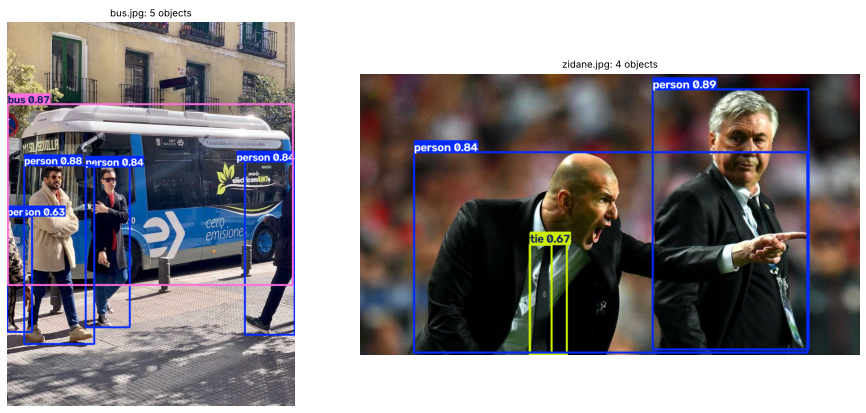

In [10]:
def yolo_report(model, path, conf=0.25, iou=0.7):
    r = model(path, conf=conf, iou=iou, verbose=False)[0]
    counts = Counter(r.names[int(c)] for c in r.boxes.cls)
    return r, counts

fig, ax = plt.subplots(1, 2, figsize=(14, 6), dpi=70)
for a, path in zip(ax, sample_images):
    r, counts = yolo_report(yolo_model, path)
    a.imshow(r.plot()[:, :, ::-1]); a.axis("off")            # plot() draws boxes+labels+scores; BGR -> RGB
    a.set_title(f"{os.path.basename(path)}: {sum(counts.values())} objects", fontsize=10)
    print(f"{os.path.basename(path)} ({r.orig_shape[1]}x{r.orig_shape[0]}) -> count per class: {dict(counts)}")
    for b, c, s in zip(r.boxes.xyxy, r.boxes.cls, r.boxes.conf):
        print(f"   {r.names[int(c)]:10s} score {s:.2f}  box {[round(v) for v in b.tolist()]}")
plt.tight_layout(); plt.show()

### 3a · The two knobs: `conf` and `iou`

- **`conf`** (default 0.25): the **score threshold**. Lower → more boxes, more of them wrong (false positives). Higher → fewer, surer boxes, but faint/small objects get missed (false negatives).
- **`iou`** (default 0.7): the **NMS threshold**. After scoring, YOLO sorts boxes and deletes any box that overlaps a better box of the same class by more than `iou`. A *low* `iou` deletes aggressively (can merge two people standing close together); a value near 1 deletes almost nothing, so **duplicate boxes on the same object survive**.

conf=0.25 iou=0.7  (default                 ) ->   5 boxes {'person': 4, 'bus': 1}


conf=0.05 iou=0.7  (low conf                ) ->   6 boxes {'person': 4, 'bus': 1, 'fire hydrant': 1}


conf=0.6  iou=0.7  (high conf               ) ->   5 boxes {'person': 4, 'bus': 1}


conf=0.05 iou=0.99 (low conf + almost no NMS) ->  48 boxes {'person': 40, 'bus': 7, 'fire hydrant': 1}


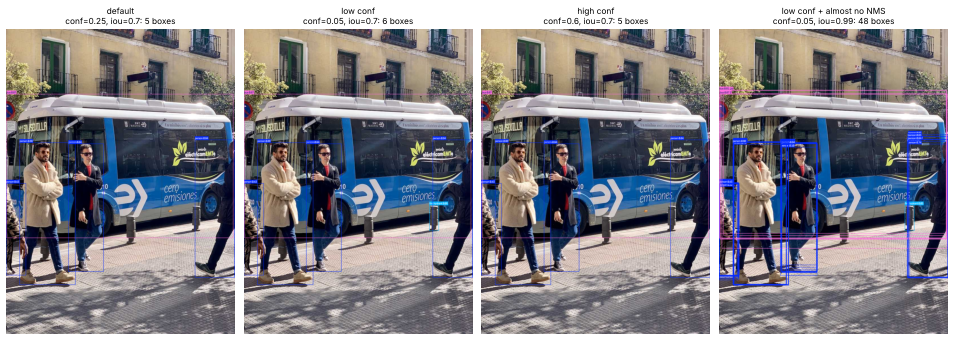

In [11]:
path = sample_images[0]
settings = [(0.25, 0.7, "default"), (0.05, 0.7, "low conf"), (0.6, 0.7, "high conf"), (0.05, 0.99, "low conf + almost no NMS")]
fig, ax = plt.subplots(1, 4, figsize=(16, 5.5), dpi=60)
for a, (c, i, label) in zip(ax, settings):
    r, counts = yolo_report(yolo_model, path, conf=c, iou=i)
    a.imshow(r.plot(font_size=8, line_width=1)[:, :, ::-1]); a.axis("off")
    a.set_title(f"{label}\nconf={c}, iou={i}: {len(r.boxes)} boxes", fontsize=10)
    print(f"conf={c:<4} iou={i:<4} ({label:24s}) -> {len(r.boxes):3d} boxes {dict(counts)}")
plt.tight_layout(); plt.show()

## 4 · Speed: how long does one image take?

The theory says one-stage detectors are fast and two-stage ones are slow. We time each available model on the same 20 COCO images (after one warm-up run, because the first call includes set-up work). Times are wall-clock on this machine's CPU limited to 2 threads; on a GPU every number drops by 10–50×.

In [12]:
yolo8 = YOLO(os.path.join(DATA, "yolov8n.pt"))
models = {"YOLOv5su (course's yolov5s)": yolo_as_torchvision(yolo_model, conf=0.25),
          "YOLOv8n": yolo_as_torchvision(yolo8, conf=0.25)}
if DETECTOR_NAME.startswith("Faster"):
    models["Faster R-CNN R50-FPN"] = detector
params = {"YOLOv5su (course's yolov5s)": sum(p.numel() for p in yolo_model.model.parameters()),
          "YOLOv8n": sum(p.numel() for p in yolo8.model.parameters()),
          "Faster R-CNN R50-FPN": sum(p.numel() for p in detector.parameters()) if DETECTOR_NAME.startswith("Faster") else None}

speed_imgs = [trainset[k][0].to(device) for k in range(20)]
speed = {}
for name, m in models.items():
    with torch.no_grad():
        m(speed_imgs[:1])                                    # warm-up
        t = time.perf_counter()
        for im in speed_imgs:
            m([im])
        speed[name] = (time.perf_counter() - t) / len(speed_imgs) * 1000
    print(f"{name:30s} {params[name]/1e6:5.1f} M parameters   {speed[name]:6.0f} ms / image   ({1000/speed[name]:4.1f} images/s)")

YOLOv5su (course's yolov5s)      9.2 M parameters      492 ms / image   ( 2.0 images/s)


YOLOv8n                          3.2 M parameters      140 ms / image   ( 7.2 images/s)


## 5 · Confidence-threshold sweep: precision vs recall

Pictures can fool you, so let's count. For every image we match each predicted box to an unmatched true box **of the same class** with IoU ≥ 0.5 (best score first):
- **precision** = correct boxes / all predicted boxes ("when it says *dog*, how often is it right?")
- **recall** = found true objects / all true objects ("how many of the dogs did it find?")

We run each YOLO model **once** at a very low threshold (0.01) on all 128 images, then apply every threshold afterwards, so the sweep costs one pass per model.

> **Honesty warning (fallback route):** COCO128 images come from COCO **train**2017, which these models were trained on, so the numbers below are **optimistic**. With the official val2017 images (the course route on your machine) you would get honest, somewhat lower numbers.

In [13]:
from torchvision.ops import box_iou

def match(pred_boxes, pred_labels, pred_scores, gt_boxes, gt_labels, iou_thr=0.5):
    """Return a True/False 'correct' flag for every prediction (greedy, best score first)."""
    correct = torch.zeros(len(pred_boxes), dtype=torch.bool)
    if len(pred_boxes) == 0 or len(gt_boxes) == 0:
        return correct
    ious = box_iou(pred_boxes, gt_boxes)
    used = torch.zeros(len(gt_boxes), dtype=torch.bool)
    for p in torch.argsort(pred_scores, descending=True):
        cand = (gt_labels == pred_labels[p]) & ~used & (ious[p] >= iou_thr)
        if cand.any():
            g = torch.where(cand)[0][ious[p][cand].argmax()]
            used[g] = True; correct[p] = True
    return correct

N_EVAL = len(trainset)
sweep_models = {"YOLOv5su": yolo_as_torchvision(yolo_model, conf=0.01), "YOLOv8n": yolo_as_torchvision(yolo8, conf=0.01)}
gts = [coco_to_xyxy(trainset[k][1]) for k in range(N_EVAL)]
n_true = sum(len(l) for _, l in gts)
records = {}
t0 = time.time()
for name, m in sweep_models.items():
    scores_all, correct_all = [], []
    for k in range(N_EVAL):
        with torch.no_grad():
            o = m([trainset[k][0]])[0]
        scores_all.append(o["scores"]); correct_all.append(match(o["boxes"], o["labels"], o["scores"], *gts[k]))
    records[name] = (torch.cat(scores_all), torch.cat(correct_all))
print(f"{N_EVAL} images, {n_true} true objects, both models evaluated in {time.time()-t0:.0f} s")

thresholds = [0.05, 0.1, 0.25, 0.4, 0.5, 0.6, 0.75, 0.9]
print(f"\n{'thresh':>6} | " + " | ".join(f"{n:^27s}" for n in records))
print(f"{'':>6} | " + " | ".join(f"{'boxes':>6} {'precision':>9} {'recall':>8}" for _ in records))
curves = {n: ([], []) for n in records}
for t in np.linspace(0.01, 0.95, 60):
    for n, (s, c) in records.items():
        k = s >= t
        curves[n][0].append(c[k].float().mean().item() if k.any() else 1.0); curves[n][1].append(c[k].sum().item() / n_true)
for t in thresholds:
    row = []
    for n, (s, c) in records.items():
        k = s >= t
        row.append(f"{int(k.sum()):6d} {c[k].float().mean().item():9.2f} {c[k].sum().item()/n_true:8.2f}")
    print(f"{t:6.2f} | " + " | ".join(row))

128 images, 929 true objects, both models evaluated in 170 s

thresh |          YOLOv5su           |           YOLOv8n          
       |  boxes precision   recall |  boxes precision   recall
  0.05 |   1526      0.46     0.75 |   1533      0.41     0.67
  0.10 |   1067      0.61     0.70 |    999      0.56     0.60
  0.25 |    688      0.80     0.59 |    604      0.76     0.50
  0.40 |    530      0.87     0.50 |    451      0.85     0.41
  0.50 |    455      0.90     0.44 |    372      0.89     0.36
  0.60 |    379      0.93     0.38 |    297      0.93     0.30
  0.75 |    259      0.97     0.27 |    203      0.97     0.21
  0.90 |     68      1.00     0.07 |     56      1.00     0.06


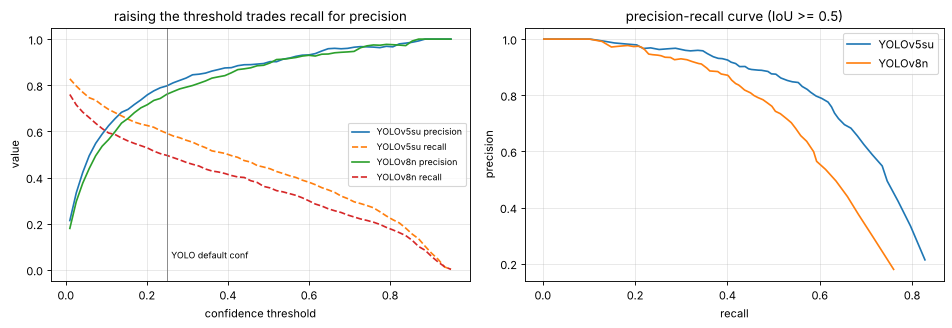

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), dpi=80)
ts = np.linspace(0.01, 0.95, 60)
for n, (p, r) in curves.items():
    ax[0].plot(ts, p, label=f"{n} precision"); ax[0].plot(ts, r, "--", label=f"{n} recall")
    ax[1].plot(r, p, label=n)
ax[0].axvline(0.25, color="grey", lw=0.8); ax[0].text(0.26, 0.05, "YOLO default conf", fontsize=8)
ax[0].set_xlabel("confidence threshold"); ax[0].set_ylabel("value"); ax[0].legend(fontsize=8); ax[0].set_title("raising the threshold trades recall for precision")
ax[1].set_xlabel("recall"); ax[1].set_ylabel("precision"); ax[1].set_title("precision-recall curve (IoU >= 0.5)"); ax[1].legend()
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 🔧 What we changed from the course notebook, and why

| Course code | Problem | Fix here |
|---|---|---|
| `CocoDetection(.., transform=Resize((224,224))+ToTensor)` | resizes the image but **not the boxes** → boxes point at the wrong pixels | `ToTensor()` only; detectors resize internally and return boxes in your image's coordinates |
| `DataLoader(trainset, batch_size=4, shuffle=True)` | default collate can't stack ragged target lists → `RuntimeError` on the first batch | `collate_fn=lambda batch: tuple(zip(*batch))` |
| `instances_train2017.json` / `train2017` (18 GB) | huge download; the pretrained model saw these images → optimistic results | `val2017` (1 GB) on your machine; COCO128 fallback here (clearly labelled optimistic) |
| `fasterrcnn_resnet50_fpn(pretrained=True)` | `pretrained=` is deprecated | `weights="DEFAULT"` |
| `outputs = model(images)` | builds a gradient graph for nothing | wrapped in `torch.no_grad()` |
| `print(len(output['boxes']))` | counts every box with score ≥ 0.05, mostly junk | also report boxes with `scores > 0.5`, draw them, compare with ground truth |
| `YOLO('yolov5s.pt')` | silently becomes `yolov5su.pt`, downloaded into the current folder | explained; saved under `data/` |
| `results.show()` | `results` is a **list** → `AttributeError` | `results[0].plot()` (or `results[0].show()` outside notebooks) |
| `print(r.names)` | prints all 80 class names, not the detections | loop over `r.boxes` (`xyxy`, `conf`, `cls`) and count per class |
| `sample.jpg` placeholder | file does not exist | downloads `bus.jpg` and `zidane.jpg` |

## Results, honestly

_(filled in after the first run)_

## Common errors and how to fix them

| Error | Cause | Fix |
|---|---|---|
| `ModuleNotFoundError: No module named 'pycocotools'` | `CocoDetection` needs it | `pip install pycocotools` |
| `RuntimeError: each element in list of batch should be of equal size` | default collate on detection targets | `collate_fn=lambda b: tuple(zip(*b))` |
| `AttributeError: 'list' object has no attribute 'show'` | `results` is a list | `results[0].show()` / `results[0].plot()` |
| `UserWarning: The parameter 'pretrained' is deprecated` | old torchvision API | `weights="DEFAULT"` |
| `URLError … download.pytorch.org` | no internet / blocked server | download the `.pth` elsewhere and put it in `~/.cache/torch/hub/checkpoints/`, or use the YOLO fallback |
| `TypeError: … expected Tensor as element 0 in argument 0` when calling the model | passed a stacked tensor or PIL images | pass a **list** of `[3,H,W]` float tensors in 0–1 |
| boxes drawn in the wrong place | resized image but not boxes, or mixed `[x,y,w,h]` with `[x1,y1,x2,y2]` | convert with `coco_to_xyxy`; don't resize for inference |
| everything detected twice | NMS `iou` set too high | keep `iou` ≈ 0.5–0.7 |

## Try this yourself

1. Change `SCORE_THRESH` to 0.3 and 0.8 in section 2. Which objects appear/disappear?
2. Run `yolo_model` on your own photo: `yolo_report(yolo_model, "my_photo.jpg")`.
3. Add `classes=[0]` to a YOLO call (`yolo_model(path, classes=[0])`) to detect only people, and count them.
4. Swap `yolov8n.pt` for `yolov8s.pt` (bigger) and redo sections 4 and 5: is the extra accuracy worth the time?
5. With the official val2017 files on disk, re-run the notebook and compare the precision/recall table with the COCO128 one.

## Run it on Google Colab with a GPU

1. Upload this notebook to Colab, then *Runtime → Change runtime type → T4 GPU*.
2. First cell: `!pip install ultralytics pycocotools`.
3. Optional (course route with real COCO val2017):
   `!mkdir -p data/coco_data && cd data/coco_data && wget -q http://images.cocodataset.org/zips/val2017.zip http://images.cocodataset.org/annotations/annotations_trainval2017.zip && unzip -q val2017.zip && unzip -q annotations_trainval2017.zip`
4. *Run all*. Faster R-CNN will download (~160 MB) and be used for section 2 and the speed race; `device` will print `cuda`.

## Viva questions

1. **What does a detector output for each object?** A box `(x1, y1, x2, y2)`, a class label and a confidence score.
2. **What is the difference between Faster R-CNN and YOLO?** Faster R-CNN is two-stage: a Region Proposal Network proposes regions, then a second head classifies/refines each. YOLO is one-stage: one pass predicts boxes and classes over a grid. Faster R-CNN is traditionally more accurate on small objects; YOLO is much faster.
3. **What do `boxes`, `labels`, `scores` contain in torchvision's output?** `[K,4]` corner coordinates in input-image pixels, `[K]` COCO category ids (1 = person), `[K]` confidences sorted high to low.
4. **Why apply a score threshold?** torchvision returns every box above 0.05; most low-score boxes are wrong. A threshold (e.g. 0.5) trades recall for precision.
5. **What is NMS and what does YOLO's `iou` parameter control?** Non-maximum suppression keeps the highest-scoring box and removes same-class boxes overlapping it by more than the IoU threshold; `iou` is that threshold.
6. **What is IoU and why 0.5?** Intersection area / union area; 0.5 is the conventional "this box found that object" cut-off (COCO also averages over 0.5–0.95).
7. **Why does the course's DataLoader crash?** Each image has a different number of objects, so the default collate can't stack targets; a custom `collate_fn` keeps them as tuples.
8. **Why is `Resize((224,224))` wrong here?** It changes image coordinates but not the box annotations; also detectors resize internally (Faster R-CNN to ~800 px, YOLO to 640) and squashing to 224 makes small objects vanish.
9. **COCO box format vs torchvision box format?** COCO `[x, y, w, h]`; torchvision `[x1, y1, x2, y2]`.
10. **Why `model.eval()` and `torch.no_grad()`?** `eval()` puts the model into inference behaviour (detection models return predictions instead of losses, batch-norm uses stored statistics); `no_grad()` skips building the gradient graph, saving memory and time.
11. **Precision vs recall?** Precision = fraction of predicted boxes that are right; recall = fraction of true objects found. Raising the confidence threshold raises precision and lowers recall.
12. **Why are results on COCO128 optimistic?** Its images are from COCO train2017, which the pretrained models trained on; evaluate on val2017 for honest numbers.
13. **What is `yolov5su.pt`?** YOLOv5-small retrained by Ultralytics with an anchor-free, YOLOv8-style head; `YOLO('yolov5s.pt')` is mapped to it.
14. **Why are COCO category ids not 0–79?** The original 91-id list had 11 ids that were never used, so the 80 real classes keep ids 1–90 with gaps; YOLO renumbers them 0–79.